# Import and Config

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from fourier_fuzzy_sets.fuzzy_classes import FourierFuzzySet, SetOps
from fourier_fuzzy_sets import Visualizer

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU available: {gpus}")

# Initialize components (replaces FourierFuzzifier)
kernel_size = 64
n = (kernel_size - 1) // 2  # Convert kernel_size to harmonics count
resolution = 100
sigma = 0.1  # Standard deviation for Gaussian fuzzification

model = FourierFuzzySet(n=n, L=1.0, resolution=resolution)
ops = SetOps(n=n, L=1.0)
visualizer = Visualizer(figsize=(7, 6))

print(f"Initialized with n={n}, kernel_size={model.kernel_size}, resolution={resolution}, sigma={sigma}")

Initialized with n=31, kernel_size=63, resolution=100, sigma=0.1


# Fuzzification

Fuzzy sample shape: (2, 63)
Evaluated shape: (2, 100)


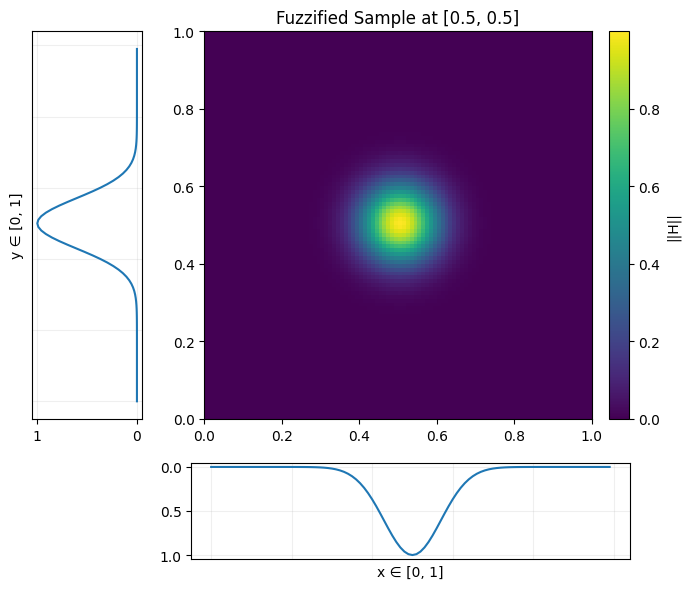

In [2]:
sample_pt = [0.5, 0.5]

# For a 2D point [x, y], create Gaussian coefficients for each dimension
# Each dimension gets a Gaussian centered at that coordinate with fixed sigma
components = tf.constant([[sample_pt[0], sigma], [sample_pt[1], sigma]], dtype=tf.float32)

# Generate Gaussian harmonics for both dimensions (shape: (2, kernel_size))
fuzzy_sample = model.get_gaussian_harmonics_batch(components, rescale=False)

# Evaluate the coefficients to get spatial distribution (shape: (2, resolution))
fuzzy_sample_evaluated = model.evaluate_batch(fuzzy_sample)

print(f"Fuzzy sample shape: {fuzzy_sample.shape}")
print(f"Evaluated shape: {fuzzy_sample_evaluated.shape}")

visualizer.plot(fuzzy_sample_evaluated, view="magnitude", title=f"Fuzzified Sample at {sample_pt}")

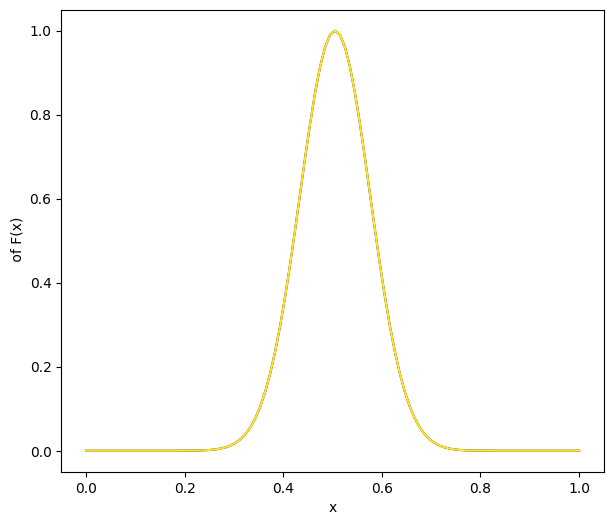

In [3]:
visualizer.plot_rows(fuzzy_sample_evaluated)

# Fuzzy Set Operations

In [4]:
offset = 0.2
sample_points = [
    [offset, offset],           # A: bottom-left
    [offset, 1-offset],         # B: top-left
    [1-offset, offset],         # C: bottom-right
    [1-offset, 1-offset],       # D: top-right
]

# Generate Gaussian coefficients for each sample point (PDFs)
# For each 2D point, create [mu, sigma] pairs for both dimensions
fuzzy_sample_point_pdfs = []
for pt in sample_points:
    components = tf.constant([[pt[0], sigma], [pt[1], sigma]], dtype=tf.float32)
    harmonics = model.get_gaussian_harmonics_batch(components, rescale=False)
    fuzzy_sample_point_pdfs.append(harmonics)

# Evaluate to get spatial distributions
fuzzy_sample_point_pdfs_evaluated = [
    model.evaluate_batch(pt)
    for pt in fuzzy_sample_point_pdfs
]

print(f"Generated {len(fuzzy_sample_point_pdfs)} sample PDFs")
print(f"Each PDF shape (coefficients): {fuzzy_sample_point_pdfs[0].shape}")
print(f"Each evaluated PDF shape: {fuzzy_sample_point_pdfs_evaluated[0].shape}")

Generated 4 sample PDFs
Each PDF shape (coefficients): (2, 63)
Each evaluated PDF shape: (2, 100)


## Negation

Negation shape: (2, 63)


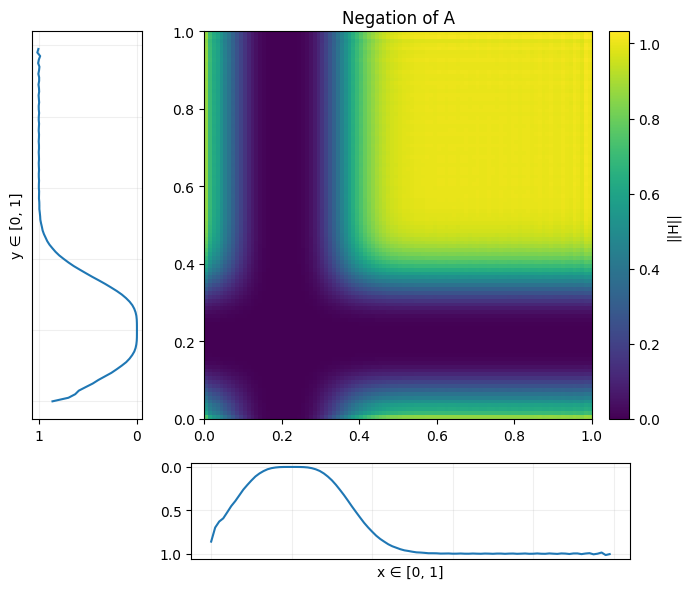

In [5]:
# SetOps expects shape (batch_size, kernel_size)
# Our PDFs are shape (2, kernel_size), so process each component separately
neg_a_components = []
for component in fuzzy_sample_point_pdfs[0]:
    # Add batch dimension, negate, remove batch dimension
    neg_component = ops.negation_batch(tf.expand_dims(component, 0))[0]
    neg_a_components.append(neg_component)

neg_a = tf.stack(neg_a_components, axis=0)
neg_a_evaluated = model.evaluate_batch(neg_a)

print(f"Negation shape: {neg_a.shape}")

visualizer.plot(
    neg_a_evaluated,
    view="magnitude",
    marginals=True,
    title="Negation of A"
)

## Union

Union shape: (2, 63)


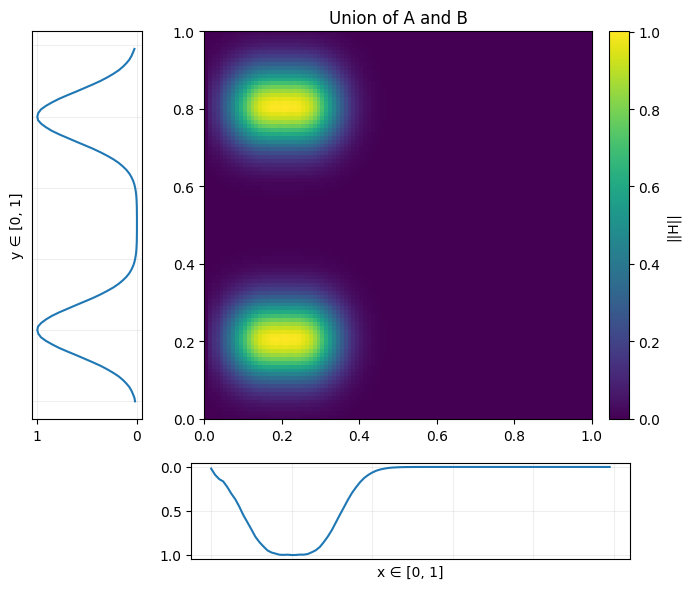

In [6]:
a_u_b_components = []
for comp_a, comp_b in zip(fuzzy_sample_point_pdfs[0], fuzzy_sample_point_pdfs[1]):
    # Add batch dimensions, union, remove batch dimension
    union_component = ops.union_batch(
        tf.expand_dims(comp_a, 0),
        tf.expand_dims(comp_b, 0)
    )[0]
    a_u_b_components.append(union_component)

a_u_b = tf.stack(a_u_b_components, axis=0)
a_u_b_evaluated = model.evaluate_batch(a_u_b)

print(f"Union shape: {a_u_b.shape}")

visualizer.plot(
    a_u_b_evaluated,
    view="magnitude",
    marginals=True,
    title="Union of A and B"
)

Component A:


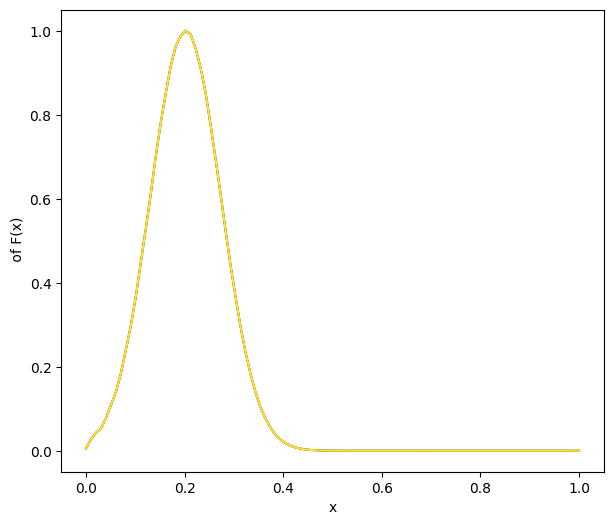


Component B:


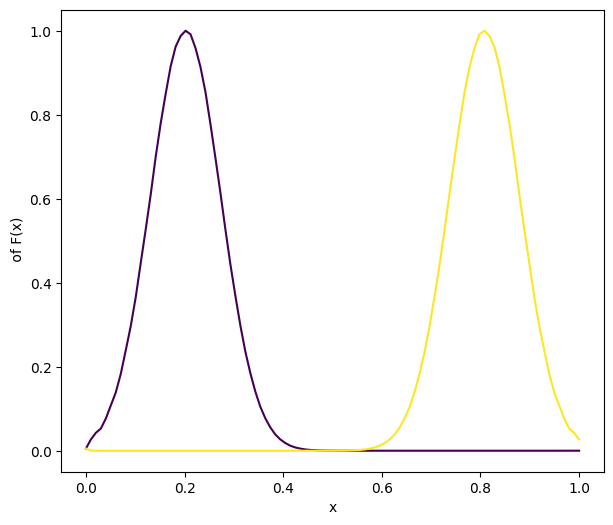


Union A ∪ B:


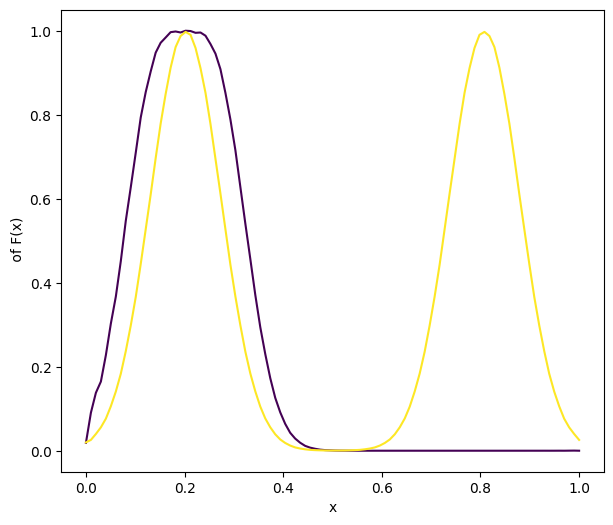

In [7]:
print("Component A:")
visualizer.plot_rows(fuzzy_sample_point_pdfs_evaluated[0])

print("\nComponent B:")
visualizer.plot_rows(fuzzy_sample_point_pdfs_evaluated[1])

print("\nUnion A ∪ B:")
visualizer.plot_rows(a_u_b_evaluated)

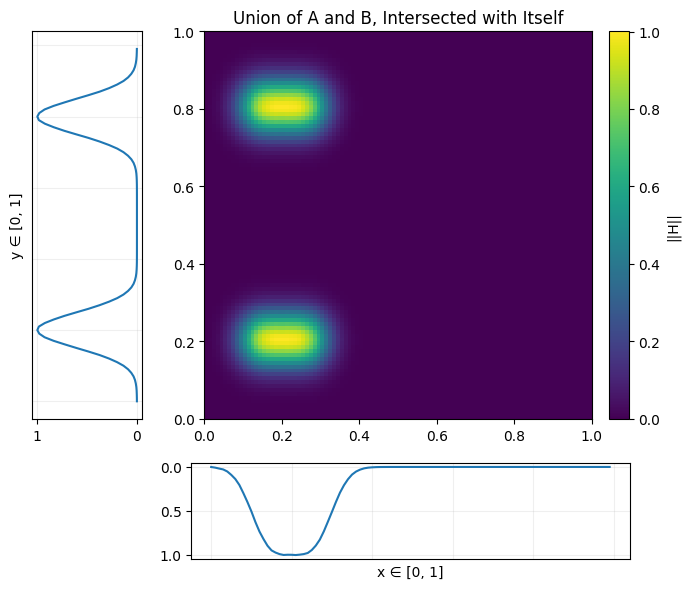

In [8]:
a_u_b_n_components = []
for comp in a_u_b:
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp, 0),
        tf.expand_dims(comp, 0)
    )[0]
    a_u_b_n_components.append(intersect_component)

a_u_b_n = tf.stack(a_u_b_n_components, axis=0)
a_u_b_n_evaluated = model.evaluate_batch(a_u_b_n)

visualizer.plot(
    a_u_b_n_evaluated,
    view="magnitude",
    marginals=True,
    title="Union of A and B, Intersected with Itself"
)

## Negation of Union

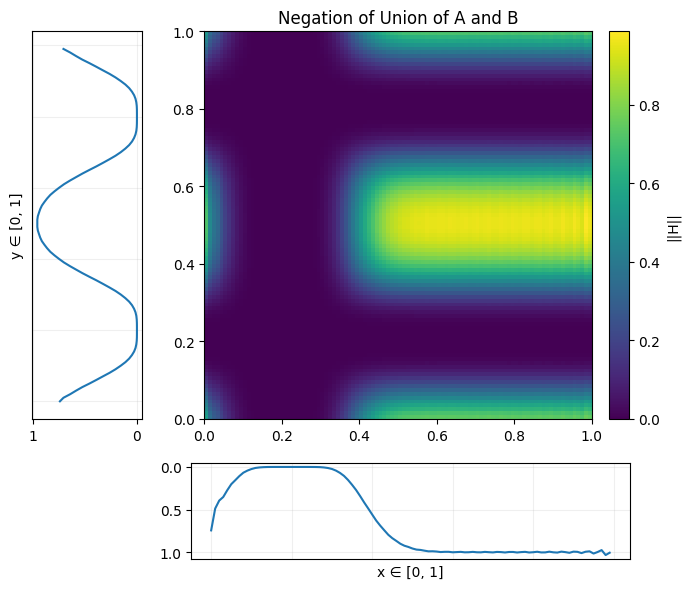

In [9]:
neg_a_u_b_components = []
for comp in a_u_b:
    neg_component = ops.negation_batch(tf.expand_dims(comp, 0))[0]
    neg_a_u_b_components.append(neg_component)

neg_a_u_b = tf.stack(neg_a_u_b_components, axis=0)
neg_a_u_b_evaluated = model.evaluate_batch(neg_a_u_b)

visualizer.plot(
    neg_a_u_b_evaluated,
    view="magnitude",
    marginals=True,
    title="Negation of Union of A and B"
)

## Intersection

Intersection shape: (2, 63)


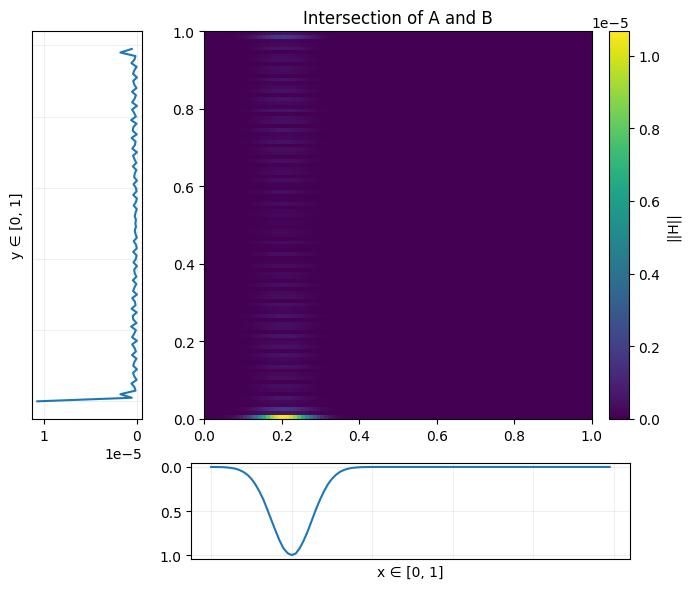

In [10]:
a_n_b_components = []
for comp_a, comp_b in zip(fuzzy_sample_point_pdfs[0], fuzzy_sample_point_pdfs[1]):
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp_a, 0),
        tf.expand_dims(comp_b, 0)
    )[0]
    a_n_b_components.append(intersect_component)

a_n_b = tf.stack(a_n_b_components, axis=0)
a_n_b_evaluated = model.evaluate_batch(a_n_b)

print(f"Intersection shape: {a_n_b.shape}")

visualizer.plot(
    a_n_b_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of A and B"
)

Component A:


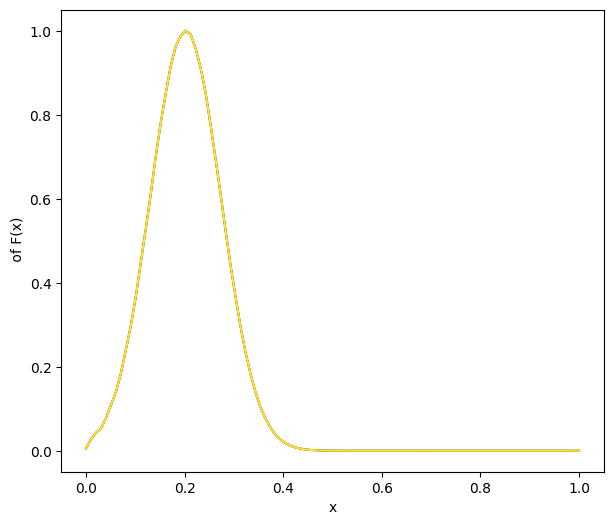


Component B:


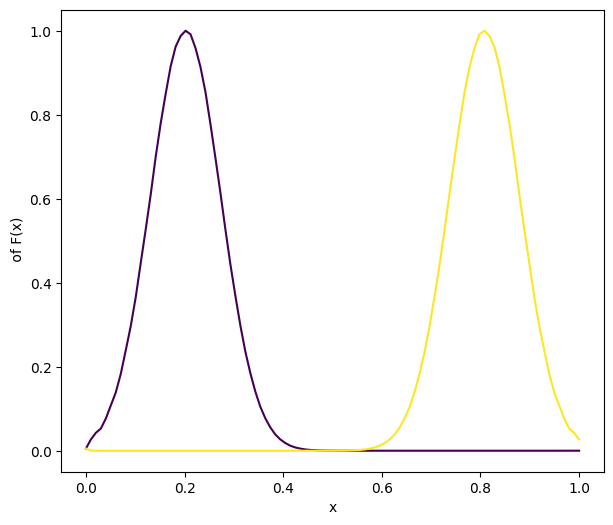


Intersection A ∩ B:


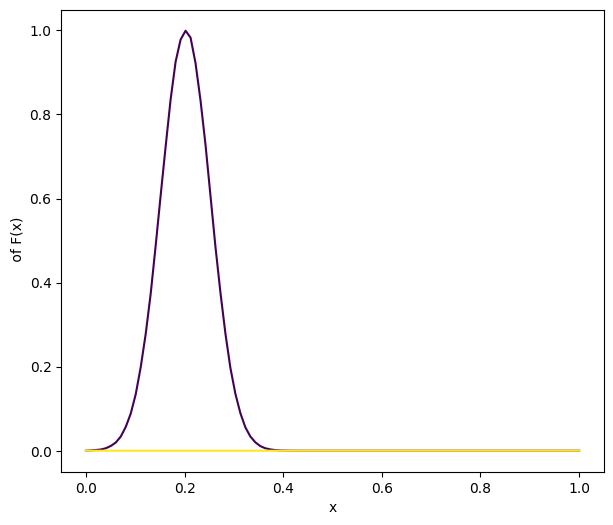

In [11]:
print("Component A:")
visualizer.plot_rows(fuzzy_sample_point_pdfs_evaluated[0])

print("\nComponent B:")
visualizer.plot_rows(fuzzy_sample_point_pdfs_evaluated[1])

print("\nIntersection A ∩ B:")
visualizer.plot_rows(a_n_b_evaluated)

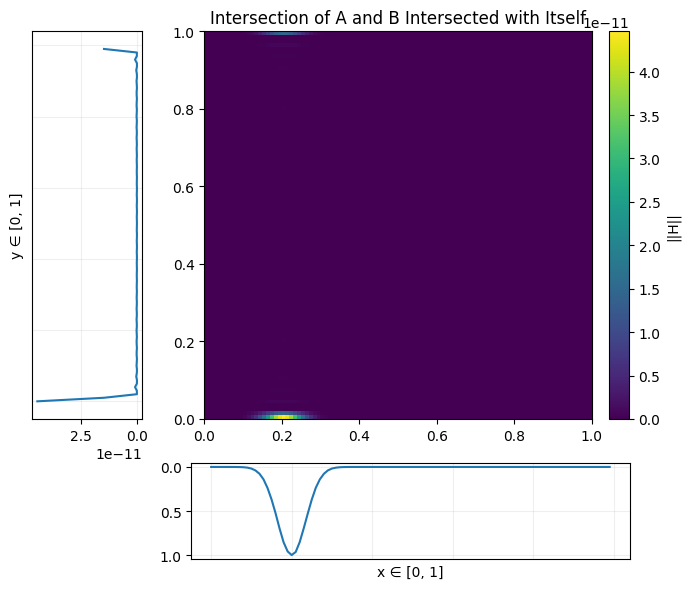

In [12]:
a_n_b_n_components = []
for comp in a_n_b:
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp, 0),
        tf.expand_dims(comp, 0)
    )[0]
    a_n_b_n_components.append(intersect_component)

a_n_b_n = tf.stack(a_n_b_n_components, axis=0)
a_n_b_n_evaluated = model.evaluate_batch(a_n_b_n)

visualizer.plot(
    a_n_b_n_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of A and B Intersected with Itself"
)

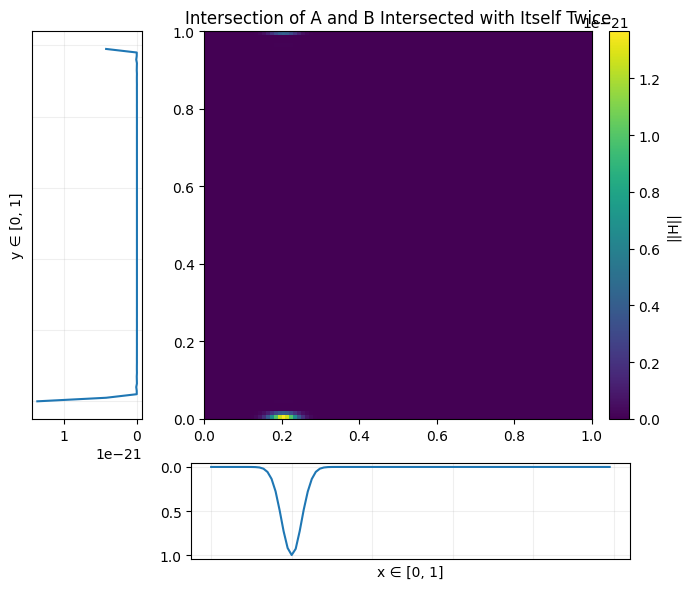

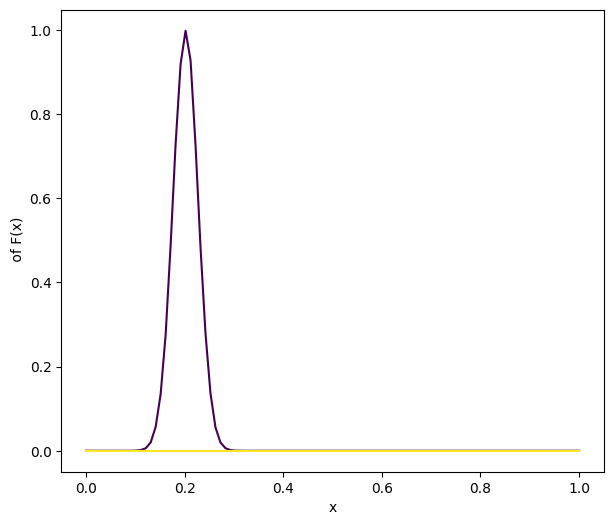

In [13]:
a_n_b_n_n_components = []
for comp in a_n_b_n:
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp, 0),
        tf.expand_dims(comp, 0)
    )[0]
    a_n_b_n_n_components.append(intersect_component)

a_n_b_n_n = tf.stack(a_n_b_n_n_components, axis=0)
a_n_b_n_n_evaluated = model.evaluate_batch(a_n_b_n_n)

visualizer.plot(
    a_n_b_n_n_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of A and B Intersected with Itself Twice"
)

visualizer.plot_rows(a_n_b_n_n_evaluated)

Intersection of (A ∩ B) intersected with C:


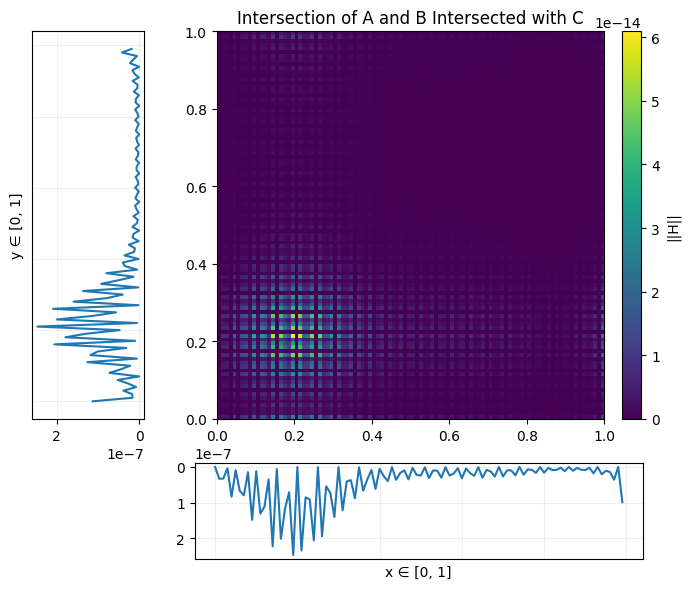

In [14]:
print("Intersection of (A ∩ B) intersected with C:")

a_n_b_n_c_components = []
for comp_ab, comp_c in zip(a_n_b, fuzzy_sample_point_pdfs[2]):
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp_ab, 0),
        tf.expand_dims(comp_c, 0)
    )[0]
    a_n_b_n_c_components.append(intersect_component)

a_n_b_n_c = tf.stack(a_n_b_n_c_components, axis=0)
a_n_b_n_c_evaluated = model.evaluate_batch(a_n_b_n_c)

visualizer.plot(
    a_n_b_n_c_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of A and B Intersected with C"
)

## Limitations of using only 1D marginal distributions

Two different distributions could have the same union and intersection when viewed through 1D marginals.

This results in confusion between component distributions and makes the set ops 1-way (information loss).

If pairwise marginals were used, though, this issue would be solved for 2D slices but persist for higher-dimensional distributions' composition.

### Union

Union of fuzzy sample A (bottom-left) with fuzzy sample D (top-right):


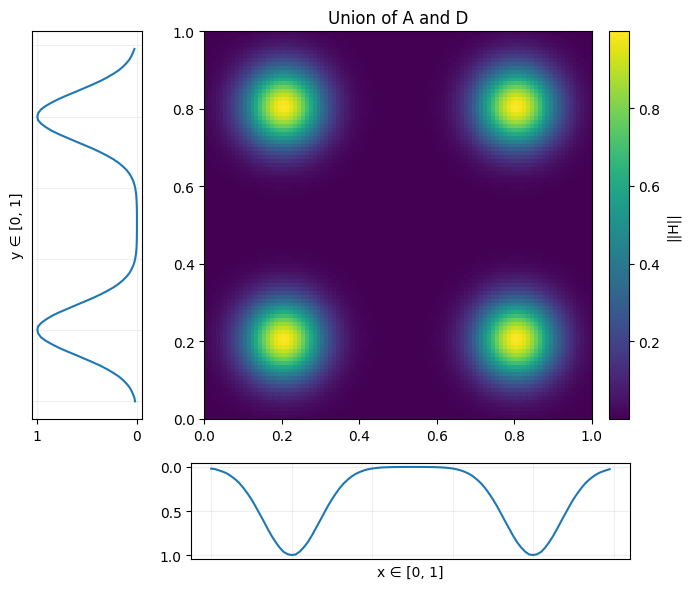


Union of fuzzy sample B (top-left) with fuzzy sample C (bottom-right):


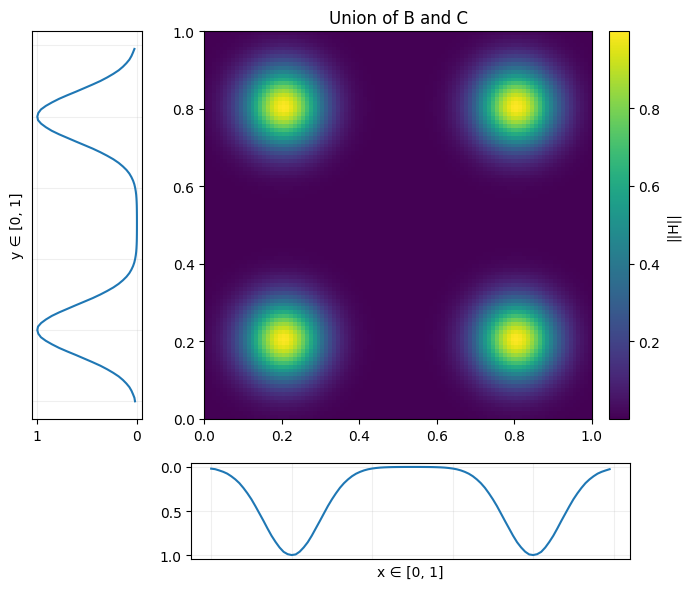


Note: The marginals (1D projections) are identical, but the 2D patterns should differ


In [15]:
# Union of A (bottom-left) with D (top-right)
a_u_d_components = []
for comp_a, comp_d in zip(fuzzy_sample_point_pdfs[0], fuzzy_sample_point_pdfs[3]):
    union_component = ops.union_batch(
        tf.expand_dims(comp_a, 0),
        tf.expand_dims(comp_d, 0)
    )[0]
    a_u_d_components.append(union_component)

a_u_d = tf.stack(a_u_d_components, axis=0)
a_u_d_evaluated = model.evaluate_batch(a_u_d)

print("Union of fuzzy sample A (bottom-left) with fuzzy sample D (top-right):")
visualizer.plot(
    a_u_d_evaluated,
    view="magnitude",
    marginals=True,
    title="Union of A and D"
)

# Union of B (top-left) with C (bottom-right)
b_u_c_components = []
for comp_b, comp_c in zip(fuzzy_sample_point_pdfs[1], fuzzy_sample_point_pdfs[2]):
    union_component = ops.union_batch(
        tf.expand_dims(comp_b, 0),
        tf.expand_dims(comp_c, 0)
    )[0]
    b_u_c_components.append(union_component)

b_u_c = tf.stack(b_u_c_components, axis=0)
b_u_c_evaluated = model.evaluate_batch(b_u_c)

print("\nUnion of fuzzy sample B (top-left) with fuzzy sample C (bottom-right):")
visualizer.plot(
    b_u_c_evaluated,
    view="magnitude",
    marginals=True,
    title="Union of B and C"
)

print("\nNote: The marginals (1D projections) are identical, but the 2D patterns should differ")

### Intersection

Intersection of fuzzy sample A (bottom-left) with fuzzy sample D (top-right):


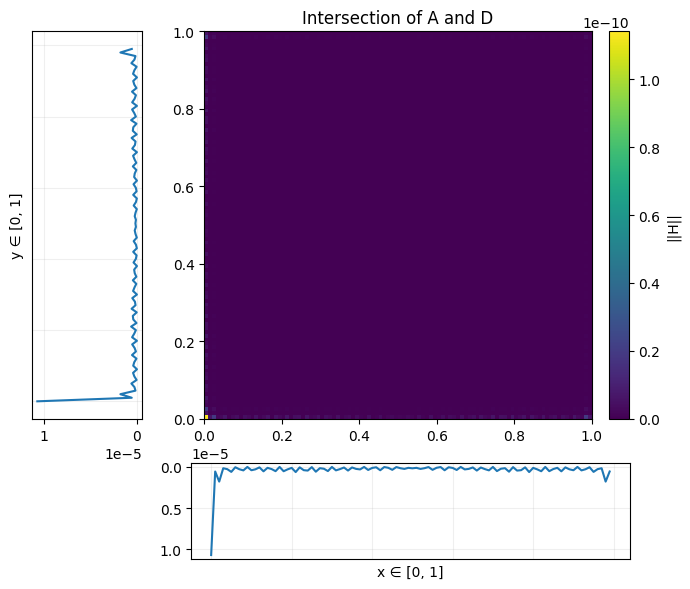


Intersection of fuzzy sample B (top-left) with fuzzy sample C (bottom-right):


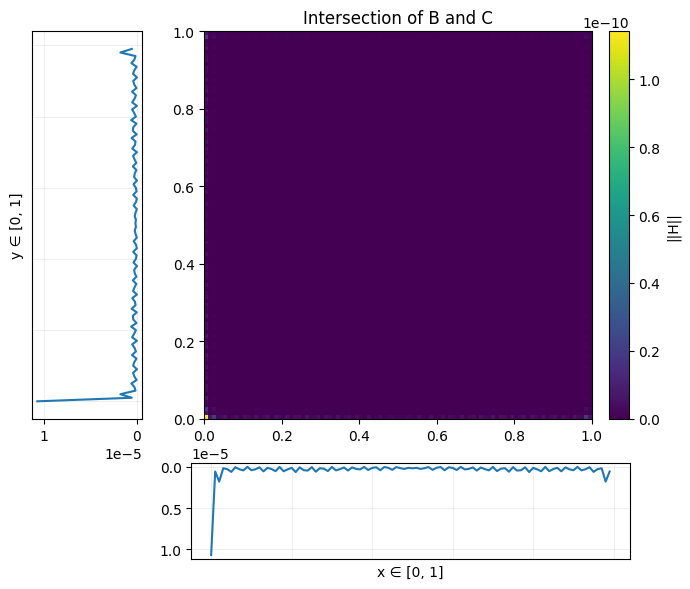


Note: Again, identical marginals but (expected) different 2D patterns


In [16]:
# Intersection of A (bottom-left) with D (top-right)
a_n_d_components = []
for comp_a, comp_d in zip(fuzzy_sample_point_pdfs[0], fuzzy_sample_point_pdfs[3]):
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp_a, 0),
        tf.expand_dims(comp_d, 0)
    )[0]
    a_n_d_components.append(intersect_component)

a_n_d = tf.stack(a_n_d_components, axis=0)
a_n_d_evaluated = model.evaluate_batch(a_n_d)

print("Intersection of fuzzy sample A (bottom-left) with fuzzy sample D (top-right):")
visualizer.plot(
    a_n_d_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of A and D"
)

# Intersection of B (top-left) with C (bottom-right)
b_n_c_components = []
for comp_b, comp_c in zip(fuzzy_sample_point_pdfs[1], fuzzy_sample_point_pdfs[2]):
    intersect_component = ops.intersect_batch(
        tf.expand_dims(comp_b, 0),
        tf.expand_dims(comp_c, 0)
    )[0]
    b_n_c_components.append(intersect_component)

b_n_c = tf.stack(b_n_c_components, axis=0)
b_n_c_evaluated = model.evaluate_batch(b_n_c)

print("\nIntersection of fuzzy sample B (top-left) with fuzzy sample C (bottom-right):")
visualizer.plot(
    b_n_c_evaluated,
    view="magnitude",
    marginals=True,
    title="Intersection of B and C"
)

print("\nNote: Again, identical marginals but (expected) different 2D patterns")